# Dihedral Distribution — MUC2 Long PTS
## Glycosylated vs Non-glycosylated

In [1]:
import os
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker
from matplotlib.colors import LogNorm

base       = "/home/computer2/analysis_simulations/analysis/dihedral_angles_15structures_mean_structure/"
output_dir = "/home/computer2/analysis_simulations/analysis/dihedral_angles_15structures_mean_structure/plots"
os.makedirs(output_dir, exist_ok=True)

RES_OFFSET = 1377   # index 0 = residue 1377 in MUC2 numbering
CLR_GLY    = "#2E86AB"
CLR_NOG    = "#A23B72"

print("Ready. Output:", output_dir)

Ready. Output: /home/computer2/analysis_simulations/analysis/dihedral_angles_15structures_mean_structure/plots


## Load Data

In [2]:
# Mean dihedrals per residue (from mean/representative structures)
gly_mean  = np.genfromtxt(base + "dihedral_glycans_mean.dat",    comments="#")
nog_mean  = np.genfromtxt(base + "dihedral_noglycans_mean.dat",  comments="#")
comp_mean = np.genfromtxt(base + "dihedral_comparison_mean.dat", comments="#")

# columns: residue_index  phi  psi
res_idx   = gly_mean[:, 0].astype(int) + RES_OFFSET
phi_gly   = gly_mean[:, 1];   psi_gly  = gly_mean[:, 2]
phi_nog   = nog_mean[:, 1];   psi_nog  = nog_mean[:, 2]
delta_phi = comp_mean[:, 5];  delta_psi = comp_mean[:, 6]

# All frames from 15 representative structures per system
import csv
def load_dist(filepath):
    phi, psi = [], []
    with open(filepath) as f:
        reader = csv.DictReader(f, delimiter='\t')
        for row in reader:
            phi.append(float(row['phi_deg']))
            psi.append(float(row['psi_deg']))
    return np.array(phi), np.array(psi)

phi_gly_all, psi_gly_all = load_dist(base + "dihedral_distribution_glycans.dat")
phi_nog_all, psi_nog_all = load_dist(base + "dihedral_distribution_noglycans.dat")

# SS per residue from mean structures (N=15 per residue)
ss_gly_ms = np.genfromtxt(base + "ss_distribution_glycans.dat",   dtype=None, encoding="utf-8", names=True)
ss_nog_ms = np.genfromtxt(base + "ss_distribution_noglycans.dat", dtype=None, encoding="utf-8", names=True)
N_MS = 15   # 15 representative structures per system

print(f"Mean residues       : {len(res_idx)}")
print(f"Glyc distribution   : {len(phi_gly_all)} dihedral values ({len(phi_gly_all)//len(res_idx)} structures × {len(res_idx)} residues)")
print(f"NoGlyc distribution : {len(phi_nog_all)} dihedral values")

# Report non-zero SS types
print("\nNon-zero SS types (mean structures):")
for col in ss_gly_ms.dtype.names:
    if 'frac' not in col:
        continue
    g = ss_gly_ms[col].astype(float)
    n = ss_nog_ms[col].astype(float)
    if g.max() > 0 or n.max() > 0:
        print(f"  {col:10s}  glyc max={g.max()*100:.1f}%  |  nog max={n.max()*100:.1f}%")

Mean residues       : 114
Glyc distribution   : 1710 dihedral values (15 structures × 114 residues)
NoGlyc distribution : 1710 dihedral values

Non-zero SS types (mean structures):
  H_frac      glyc max=0.0%  |  nog max=6.7%
  C_frac      glyc max=100.0%  |  nog max=100.0%
  G_frac      glyc max=0.0%  |  nog max=6.7%
  T_frac      glyc max=6.7%  |  nog max=26.7%
  B_frac      glyc max=0.0%  |  nog max=6.7%
  S_frac      glyc max=26.7%  |  nog max=66.7%


## Figure 1 — Ramachandran Plot (All Frames)

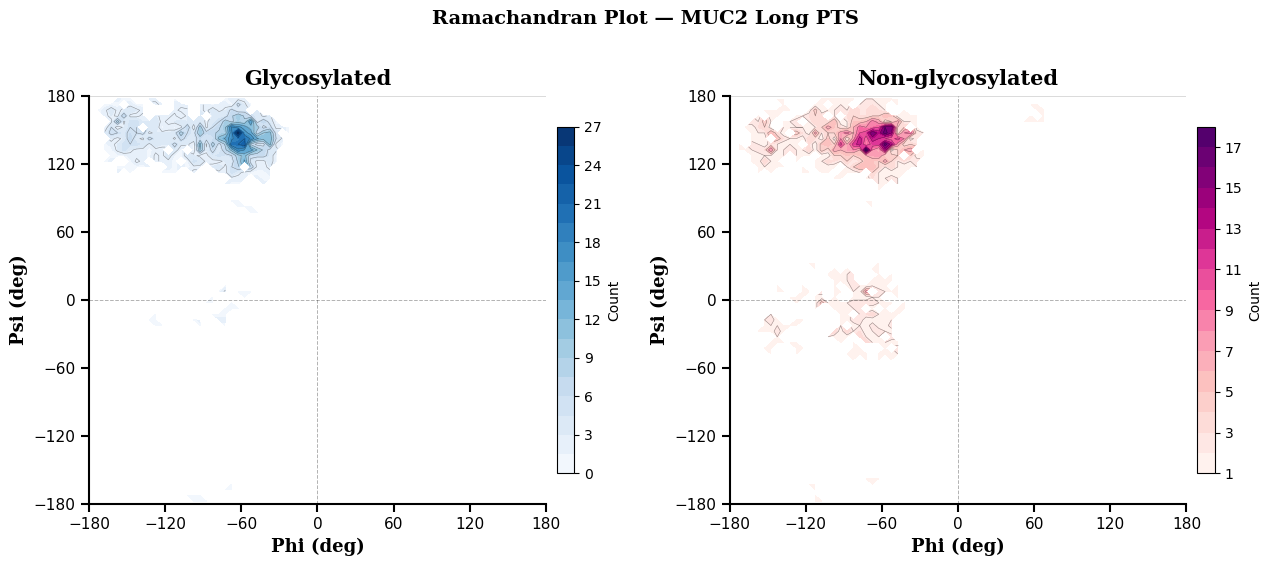

Saved: /home/computer2/analysis_simulations/analysis/dihedral_angles_15structures_mean_structure/plots/ramachandran.png


In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5.5), dpi=100)
fig.set_facecolor("white")

bins = np.linspace(-180, 180, 73)   # 5 deg bins

for ax, phi, psi, title, cmap in [
    (axes[0], phi_gly_all, psi_gly_all, "Glycosylated",     "Blues"),
    (axes[1], phi_nog_all, psi_nog_all, "Non-glycosylated",  "RdPu"),
]:
    h, xe, ye = np.histogram2d(phi, psi, bins=bins)
    h = np.where(h == 0, np.nan, h)
    xc = 0.5 * (xe[:-1] + xe[1:])
    yc = 0.5 * (ye[:-1] + ye[1:])

    im = ax.contourf(xc, yc, h.T, levels=20, cmap=cmap)
    ax.contour(xc, yc, h.T, levels=10, colors="black", linewidths=0.4, alpha=0.4)

    plt.colorbar(im, ax=ax, shrink=0.85, pad=0.02, label="Count")

    # Reference lines
    ax.axhline(0,   color="black", linewidth=0.7, linestyle="--", alpha=0.3)
    ax.axvline(0,   color="black", linewidth=0.7, linestyle="--", alpha=0.3)
    ax.axhline(-180, color="black", linewidth=0.5, alpha=0.2)
    ax.axhline( 180, color="black", linewidth=0.5, alpha=0.2)

    ax.set_xlim(-180, 180)
    ax.set_ylim(-180, 180)
    ax.set_xlabel("Phi (deg)", fontsize=13, fontname="DejaVu Serif", fontweight="bold")
    ax.set_ylabel("Psi (deg)", fontsize=13, fontname="DejaVu Serif", fontweight="bold")
    ax.set_title(title, fontsize=15, fontname="DejaVu Serif", fontweight="bold", pad=8)
    ax.set_facecolor("white")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_linewidth(1.5)
    ax.spines["bottom"].set_linewidth(1.5)
    ax.tick_params(axis="both", labelsize=11, length=6, width=1.5, direction="out")
    ax.xaxis.set_major_locator(ticker.MultipleLocator(60))
    ax.yaxis.set_major_locator(ticker.MultipleLocator(60))

fig.suptitle("Ramachandran Plot — MUC2 Long PTS",
             fontsize=14, fontname="DejaVu Serif", fontweight="bold", y=1.02)
plt.tight_layout()
out = os.path.join(output_dir, "ramachandran.png")
plt.savefig(out, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved: {out}")

## Figure 2 — Per-residue Mean Phi and Psi

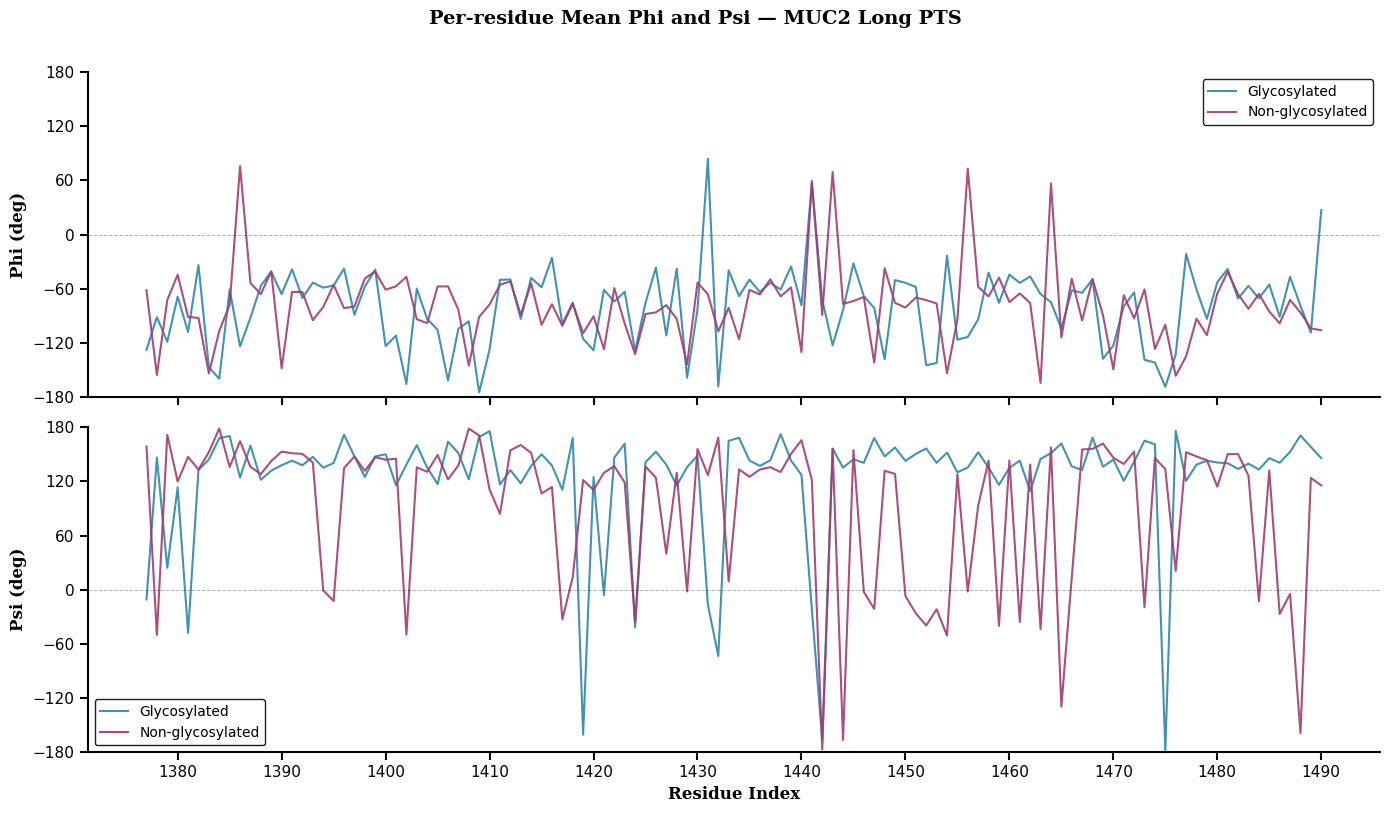

Saved: /home/computer2/analysis_simulations/analysis/dihedral_angles_15structures_mean_structure/plots/per_residue_dihedrals.png


In [4]:
fig, axes = plt.subplots(2, 1, figsize=(14, 8), dpi=100, sharex=True)
fig.set_facecolor("white")

for ax, gly_vals, nog_vals, ylabel, ylim in [
    (axes[0], phi_gly, phi_nog, "Phi (deg)", (-180, 180)),
    (axes[1], psi_gly, psi_nog, "Psi (deg)", (-180, 180)),
]:
    ax.plot(res_idx, gly_vals, color=CLR_GLY, linewidth=1.5, alpha=0.9, label="Glycosylated")
    ax.plot(res_idx, nog_vals, color=CLR_NOG, linewidth=1.5, alpha=0.9, label="Non-glycosylated")
    ax.axhline(0, color="black", linewidth=0.7, linestyle="--", alpha=0.3)
    ax.set_ylabel(ylabel, fontsize=12, fontname="DejaVu Serif", fontweight="bold")
    ax.set_ylim(ylim)
    ax.legend(fontsize=10, framealpha=0.88, edgecolor="black")
    ax.set_facecolor("white")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_linewidth(1.5)
    ax.spines["bottom"].set_linewidth(1.5)
    ax.tick_params(axis="both", labelsize=11, length=6, width=1.5, direction="out")
    ax.yaxis.set_major_locator(ticker.MultipleLocator(60))

axes[1].set_xlabel("Residue Index", fontsize=12, fontname="DejaVu Serif", fontweight="bold")
axes[0].xaxis.set_major_locator(ticker.MultipleLocator(10))

fig.suptitle("Per-residue Mean Phi and Psi — MUC2 Long PTS",
             fontsize=14, fontname="DejaVu Serif", fontweight="bold", y=1.01)
plt.tight_layout()
out = os.path.join(output_dir, "per_residue_dihedrals.png")
plt.savefig(out, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved: {out}")

## Figure 3 — Delta Phi and Delta Psi (Glyc minus NoGlyc)

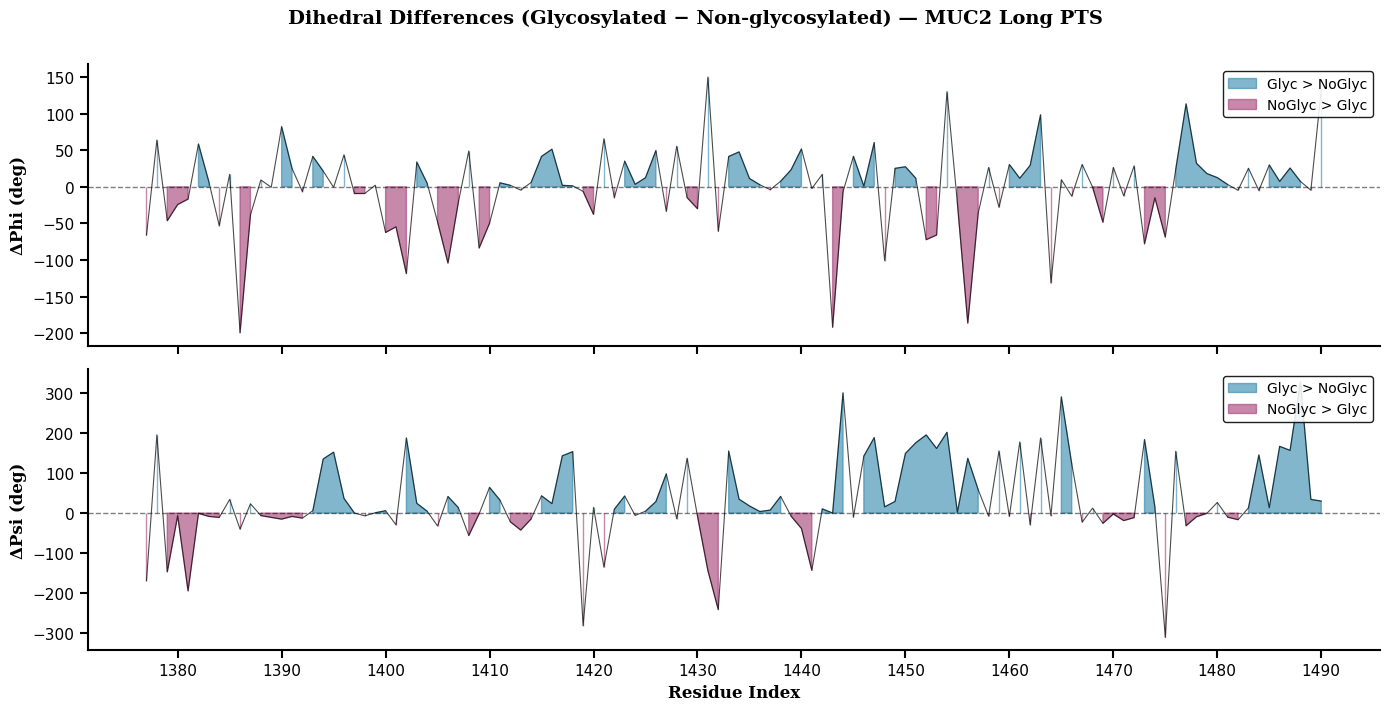

Saved: /home/computer2/analysis_simulations/analysis/dihedral_angles_15structures_mean_structure/plots/dihedral_differences.png


In [5]:
fig, axes = plt.subplots(2, 1, figsize=(14, 7), dpi=100, sharex=True)
fig.set_facecolor("white")

for ax, delta, ylabel in [
    (axes[0], delta_phi, "\u0394Phi (deg)"),
    (axes[1], delta_psi, "\u0394Psi (deg)"),
]:
    ax.fill_between(res_idx, delta, 0,
                    where=(delta > 0), color=CLR_GLY, alpha=0.6, label="Glyc > NoGlyc")
    ax.fill_between(res_idx, delta, 0,
                    where=(delta < 0), color=CLR_NOG, alpha=0.6, label="NoGlyc > Glyc")
    ax.plot(res_idx, delta, color="black", linewidth=0.8, alpha=0.7)
    ax.axhline(0, color="black", linewidth=1.0, linestyle="--", alpha=0.5)
    ax.set_ylabel(ylabel, fontsize=12, fontname="DejaVu Serif", fontweight="bold")
    ax.legend(fontsize=10, framealpha=0.88, edgecolor="black", loc="upper right")
    ax.set_facecolor("white")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_linewidth(1.5)
    ax.spines["bottom"].set_linewidth(1.5)
    ax.tick_params(axis="both", labelsize=11, length=6, width=1.5, direction="out")

axes[1].set_xlabel("Residue Index", fontsize=12, fontname="DejaVu Serif", fontweight="bold")
axes[0].xaxis.set_major_locator(ticker.MultipleLocator(10))

fig.suptitle("Dihedral Differences (Glycosylated \u2212 Non-glycosylated) — MUC2 Long PTS",
             fontsize=14, fontname="DejaVu Serif", fontweight="bold", y=1.01)
plt.tight_layout()
out = os.path.join(output_dir, "dihedral_differences.png")
plt.savefig(out, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved: {out}")

## Figure 4 — Ramachandran Overlay (Mean values per residue)

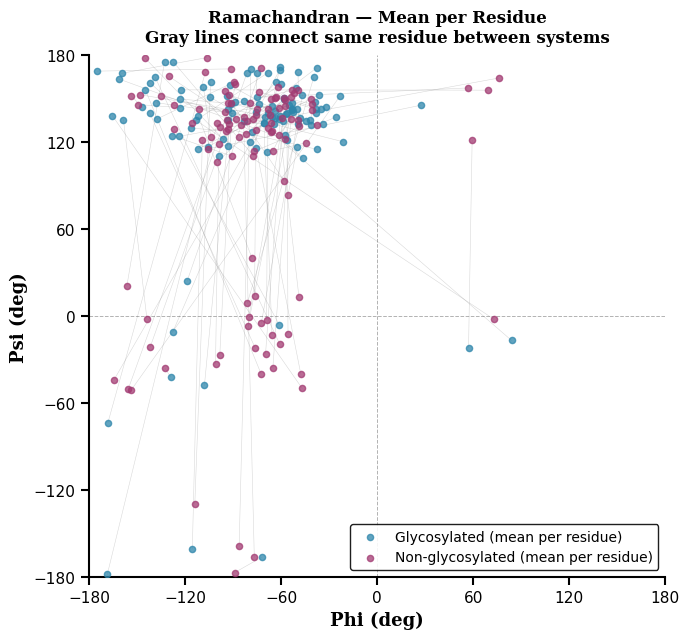

Saved: /home/computer2/analysis_simulations/analysis/dihedral_angles_15structures_mean_structure/plots/ramachandran_overlay.png


In [6]:
fig, ax = plt.subplots(figsize=(7, 6.5), dpi=100)
fig.set_facecolor("white")

ax.scatter(phi_gly, psi_gly, color=CLR_GLY, s=20, alpha=0.75,
           label="Glycosylated (mean per residue)", zorder=3)
ax.scatter(phi_nog, psi_nog, color=CLR_NOG, s=20, alpha=0.75,
           label="Non-glycosylated (mean per residue)", zorder=3)

# Connect same residue between systems
for pg, ps_g, pn, ps_n in zip(phi_gly, psi_gly, phi_nog, psi_nog):
    ax.plot([pg, pn], [ps_g, ps_n], color="gray", linewidth=0.4, alpha=0.3, zorder=1)

ax.axhline(0,    color="black", linewidth=0.7, linestyle="--", alpha=0.3)
ax.axvline(0,    color="black", linewidth=0.7, linestyle="--", alpha=0.3)
ax.set_xlim(-180, 180)
ax.set_ylim(-180, 180)
ax.set_xlabel("Phi (deg)", fontsize=13, fontname="DejaVu Serif", fontweight="bold")
ax.set_ylabel("Psi (deg)", fontsize=13, fontname="DejaVu Serif", fontweight="bold")
ax.set_title("Ramachandran — Mean per Residue\nGray lines connect same residue between systems",
             fontsize=12, fontname="DejaVu Serif", fontweight="bold", pad=10)
ax.legend(fontsize=10, framealpha=0.88, edgecolor="black")
ax.set_facecolor("white")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_linewidth(1.5)
ax.spines["bottom"].set_linewidth(1.5)
ax.tick_params(axis="both", labelsize=11, length=6, width=1.5, direction="out")
ax.xaxis.set_major_locator(ticker.MultipleLocator(60))
ax.yaxis.set_major_locator(ticker.MultipleLocator(60))

plt.tight_layout()
out = os.path.join(output_dir, "ramachandran_overlay.png")
plt.savefig(out, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved: {out}")

## Figure 5 — Secondary Structure per Residue (Mean Structures, N=15)

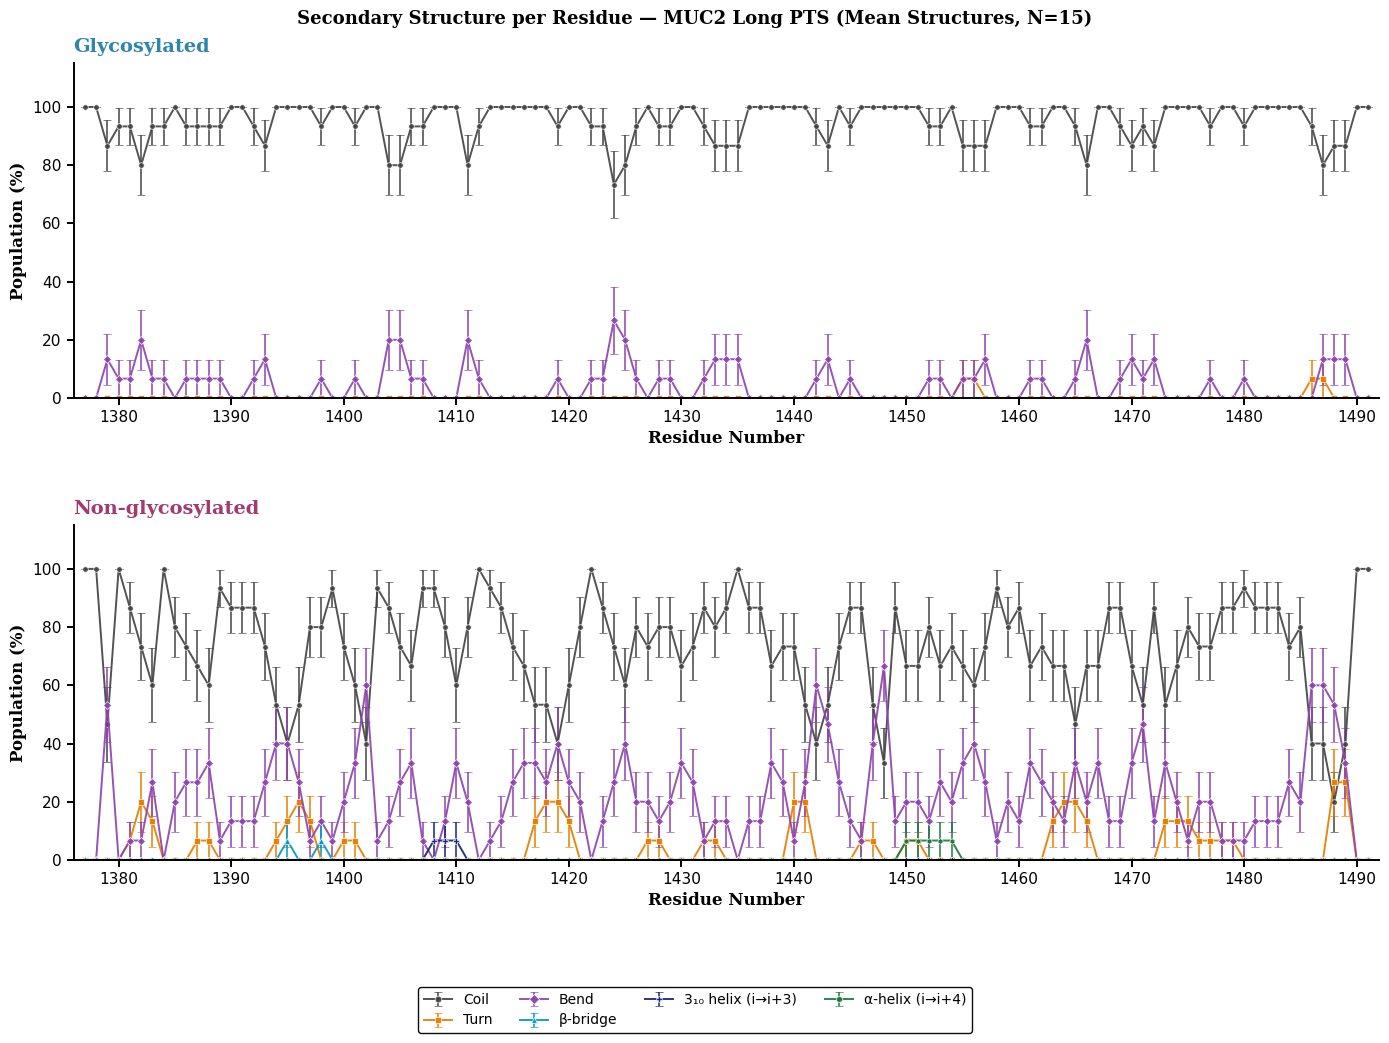

Saved: /home/computer2/analysis_simulations/analysis/dihedral_angles_15structures_mean_structure/plots/ss_per_residue_mean_structures.png


In [7]:
res_ss = ss_gly_ms['residue_index'].astype(int) + RES_OFFSET

ss_styles = {
    "C_frac": {"label": "Coil",              "color": "#444444", "marker": "o", "ms": 4},
    "T_frac": {"label": "Turn",              "color": "#E67E00", "marker": "s", "ms": 4},
    "S_frac": {"label": "Bend",              "color": "#8E44AD", "marker": "D", "ms": 4},
    "B_frac": {"label": "\u03B2-bridge",     "color": "#0099CC", "marker": "^", "ms": 4},
    "E_frac": {"label": "\u03B2-strand",     "color": "#C0392B", "marker": "v", "ms": 4},
    "G_frac": {"label": "3\u2081\u2080 helix (i\u2192i+3)", "color": "#1A237E", "marker": "P", "ms": 4},
    "H_frac": {"label": "\u03B1-helix (i\u2192i+4)",       "color": "#1B7A3E", "marker": "h", "ms": 4},
    "I_frac": {"label": "\u03C0-helix (i\u2192i+5)",       "color": "#B03060", "marker": "*", "ms": 5},
}

fig, axes = plt.subplots(2, 1, figsize=(14, 10), dpi=100)
fig.set_facecolor("white")

for ax, dat, system_label, sys_color in [
    (axes[0], ss_gly_ms, "Glycosylated",    CLR_GLY),
    (axes[1], ss_nog_ms, "Non-glycosylated", CLR_NOG),
]:
    for col, style in ss_styles.items():
        if col not in dat.dtype.names:
            continue
        p   = dat[col].astype(float)
        pct = p * 100
        se  = np.sqrt(p * (1 - p) / N_MS) * 100   # binomial SE, N=15
        if pct.max() < 0.001:
            continue
        ax.errorbar(res_ss, pct, yerr=se,
                    color=style["color"], marker=style["marker"],
                    markersize=style["ms"], linewidth=1.4,
                    markerfacecolor=style["color"],
                    markeredgewidth=0.5, markeredgecolor="white",
                    elinewidth=1.2, capsize=3, capthick=1.2,
                    ecolor=style["color"], alpha=0.92,
                    label=style["label"])

    ax.set_title(system_label, fontsize=14, fontname="DejaVu Serif",
                 fontweight="bold", color=sys_color, pad=8, loc="left")
    ax.set_ylabel("Population (%)", fontsize=12,
                  fontname="DejaVu Serif", fontweight="bold")
    ax.set_xlabel("Residue Number", fontsize=12,
                  fontname="DejaVu Serif", fontweight="bold")
    ax.set_xlim(res_ss[0] - 1, res_ss[-1] + 1)
    ax.set_ylim(0, 115)
    ax.yaxis.set_major_locator(ticker.MultipleLocator(20))
    ax.xaxis.set_major_locator(ticker.MultipleLocator(10))
    ax.set_facecolor("white")
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_linewidth(1.4)
    ax.spines["bottom"].set_linewidth(1.4)
    ax.tick_params(labelsize=11, length=5, width=1.4, direction="out")

handles_all, labels_all = axes[1].get_legend_handles_labels()
# fallback to axes[0] if axes[1] has fewer types
if len(handles_all) < len(axes[0].get_legend_handles_labels()[0]):
    handles_all, labels_all = axes[0].get_legend_handles_labels()
fig.legend(handles=handles_all, labels=labels_all,
           loc="lower center", bbox_to_anchor=(0.5, -0.05),
           ncol=4, fontsize=10, framealpha=0.95, edgecolor="black", markerscale=1.2)

fig.suptitle("Secondary Structure per Residue — MUC2 Long PTS (Mean Structures, N=15)",
             fontsize=13, fontname="DejaVu Serif", fontweight="bold")
plt.tight_layout()
plt.subplots_adjust(hspace=0.38, bottom=0.13)
out = os.path.join(output_dir, "ss_per_residue_mean_structures.png")
plt.savefig(out, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved: {out}")

## Figure 6 — Overall Secondary Structure Summary (Mean Structures)

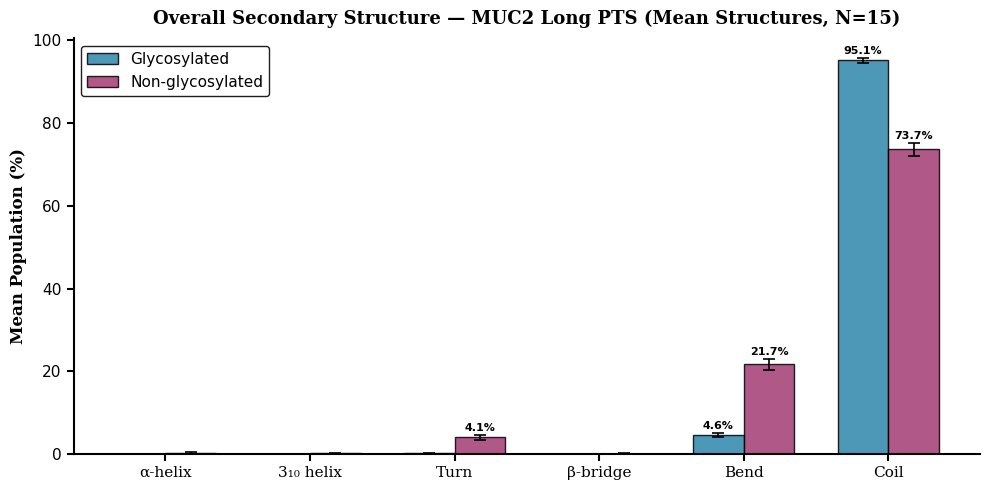

Saved: /home/computer2/analysis_simulations/analysis/dihedral_angles_15structures_mean_structure/plots/ss_overall_mean_structures.png


In [8]:
ss_code_labels = {
    "H_frac": "\u03B1-helix",    "E_frac": "\u03B2-strand",
    "G_frac": "3\u2081\u2080 helix", "I_frac": "\u03C0-helix",
    "T_frac": "Turn",             "B_frac": "\u03B2-bridge",
    "S_frac": "Bend",             "C_frac": "Coil",
}

names, pct_gly, pct_nog, se_gly, se_nog = [], [], [], [], []
for col, label in ss_code_labels.items():
    if col not in ss_gly_ms.dtype.names:
        continue
    g = ss_gly_ms[col].astype(float)
    n = ss_nog_ms[col].astype(float)
    gm = g.mean() * 100;  nm = n.mean() * 100
    if gm < 0.001 and nm < 0.001:
        continue
    names.append(label)
    pct_gly.append(gm);  pct_nog.append(nm)
    # SE of the mean across residues
    se_gly.append(g.std() / np.sqrt(len(g)) * 100)
    se_nog.append(n.std() / np.sqrt(len(n)) * 100)

fig, ax = plt.subplots(figsize=(10, 5), dpi=100)
fig.set_facecolor("white")

x = np.arange(len(names))
w = 0.35
bars1 = ax.bar(x - w/2, pct_gly, width=w, color=CLR_GLY, alpha=0.85,
               edgecolor="black", linewidth=1.0, label="Glycosylated",
               yerr=se_gly, error_kw=dict(elinewidth=1.2, capsize=4, capthick=1.2, ecolor="black"))
bars2 = ax.bar(x + w/2, pct_nog, width=w, color=CLR_NOG, alpha=0.85,
               edgecolor="black", linewidth=1.0, label="Non-glycosylated",
               yerr=se_nog, error_kw=dict(elinewidth=1.2, capsize=4, capthick=1.2, ecolor="black"))

for bar, err in list(zip(bars1, se_gly)) + list(zip(bars2, se_nog)):
    h = bar.get_height()
    if h > 0.5:
        ax.text(bar.get_x() + bar.get_width()/2, h + err + 0.5,
                f"{h:.1f}%", ha="center", va="bottom", fontsize=8, fontweight="bold")

ax.set_xticks(x)
ax.set_xticklabels(names, fontsize=11, fontname="DejaVu Serif")
ax.set_ylabel("Mean Population (%)", fontsize=12,
              fontname="DejaVu Serif", fontweight="bold")
ax.set_title("Overall Secondary Structure — MUC2 Long PTS (Mean Structures, N=15)",
             fontsize=13, fontname="DejaVu Serif", fontweight="bold", pad=10)
ax.legend(fontsize=11, framealpha=0.88, edgecolor="black")
ax.set_facecolor("white")
ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)
ax.spines["left"].set_linewidth(1.5)
ax.spines["bottom"].set_linewidth(1.5)
ax.tick_params(labelsize=11, length=5, width=1.5, direction="out")

plt.tight_layout()
out = os.path.join(output_dir, "ss_overall_mean_structures.png")
plt.savefig(out, dpi=300, bbox_inches="tight", facecolor="white")
plt.show()
print(f"Saved: {out}")